# CNN calibration for TWx — single station, small predictor domain

**Reproducible example of the CNN1.SD configuration** used for statistical downscaling of TWx at a meteorological station.

**Workflow:** 

-ERA5 predictors and station observations 

-station and domain selection 

-standardization 

-CNN architecture → training → independent prediction  

-plots.

This notebook illustrates a single final model fit using training data from 1991–2020 and its application to the independent 2023–2024 austral summer (hereafter, summer 2024).

It does not reproduce the full set of experiments conducted in the study, including the cross-validation procedure. No results are precomputed; the notebook must be executed on the server with access to the original datasets and required software packages.

No GPU is required to run this example.

## 1. Environment and packages
Run this notebook with an R kernel that has access to `cnn-hs`, `climate4R`, and `downscaleR.keras`. Adjust the paths for your installation.

In [1]:
options(java.parameters = "-Xmx32g")
Sys.setenv(RETICULATE_PYTHON = "/nfs/home/gmeteo/balmacedar/micromamba/envs/cnn-hs/bin/python")

library(reticulate)
library(keras)
keras::py_require_legacy_keras()
library(tensorflow)
library(loadeR)
library(transformeR)
library(visualizeR)
library(downscaleR.keras)
library(magrittr)

set.seed(42)
tensorflow::tf$random$set_seed(42L)

The keras package is deprecated. Use the keras3 package instead.

Loading required package: rJava

Loading required package: loadeR.java

Java version 23x amd64 by N/A detected

The maximum JVM heap space available is: 32.00 GB

NetCDF Java Library Version: 4.6.0-SNAPSHOT (Built-On: 20150423.1338) loaded and ready

You can manually set the NetCDF Java Library version before loading the package:
options(loadeR.java_forced_version = "X.Y.Z")
library(loadeR.java)

netCDF-Java CLASSPATH from bundled java package directory: /nfs/home/gmeteo/balmacedar/micromamba/envs/cnn-hs/lib/R/library/loadeR.java/java:/nfs/home/gmeteo/balmacedar/micromamba/envs/cnn-hs/lib/R/library/loadeR.java/java/netcdfAll-4.6.0-SNAPSHOT.jar

Loading required package: climate4R.UDG

climate4R.UDG version 0.2.6 (2023-06-26) is loaded

Please use 'citation("climate4R.UDG")' to cite this package.

loadeR version 1.8.4 (2025-08-07) is loaded

Please use 'citation("loadeR")' to cite this package.




    _______   ____  ___________________  __  ________ 
   / ___/ /  / /  |/  / __  /_  __/ __/ / / / / __  / 
  / /  / /  / / /|_/ / /_/ / / / / __/ / /_/ / /_/_/  
 / /__/ /__/ / /  / / __  / / / / /__ /___  / / \ \ 
 \___/____/_/_/  /_/_/ /_/ /_/  \___/    /_/\/   \_\ 
 
      github.com/SantanderMetGroup/climate4R



transformeR version 2.2.2 (2023-10-26) is loaded


Get the latest stable version (2.2.5) using <devtools::install_github('SantanderMetGroup/transformeR')>

Please see 'citation("transformeR")' to cite this package.

visualizeR version 1.6.4 (2023-10-26) is loaded

Please see 'citation("visualizeR")' to cite this package.

Loading required package: downscaleR

downscaleR version 3.3.4 (2023-06-22) is loaded

Please use 'citation("downscaleR")' to cite this package.



## 2. Example settings
This example uses TWx, ReLU activation, and **one filter in the final convolutional layer** (`CNN10.SD`). Choose another station by changing `station_index` or selecting its identifier.

In [2]:
var <- "twmax"
activation <- "relu"
summer="23_24"

# Training hyperparameters
batch_size <- 100L
max_epochs <- 10000L
patience <- 30L
learning_rate <- 1e-4

# Gaussian loss
distribution <- "gaussianLoss"
distribution_fun <- gaussianLoss(last.connection = "dense")

## 3. Load predictors and observations
The original `.Rdata` files are assumed to contain `climate4R` data objects.

In [25]:
base_path <- "/lustre/gmeteo/WORK/balmacedar/CNN_HS"
source(paste0(base_path,"/downscaleTrain.keras_history.r"))

# File with only one object
load_one <- function(filename) {
  e <- new.env(parent = emptyenv())
  obj_name <- load(filename, envir = e)
  stopifnot(length(obj_name) == 1L)
  get(obj_name, envir = e)
}

x_all <- load_one(file.path(base_path, "x_files.Rdata"))
y_all <- load_one(file.path(base_path, "TWx", "new_station_data", "y_files.Rdata"))
x_summer_2024 <- load_one(file.path(base_path, "x_2024_files.Rdata"))

station_ids <- y_all$Metadata$station_id
station_name <- y_all$Metadata$name


In [ ]:
## Align dates and standarized predictors from summer 2024 using the same training reference ###

y=getTemporalIntersection(obs=y_all,prd=x_all,which.return = "obs")

y$Dates$start=x_all$Dates[[1]]$start
y$Dates$end=x_all$Dates[[1]]$end

x_all=getTemporalIntersection(obs=y,prd=x_all,which.return = "prd")

x_2024=subsetGrid(x_summer_2024, season = c(12,1,2))
x_2024 <- scaleGrid(grid = x_2024, base = subsetGrid(x_all, season = c(12,1,2)),type = "standardize") #to conserve same summer format 12,1,2

[2026-10-20 14:23:00.84043] - Scaling ...

NOTE: Some data will be lost on year-crossing season subset (see the 'Time slicing' section of subsetGrid documentation for more details)

[2026-10-20 14:23:14.198031] - Done



In [27]:
nsta <- getShape(y, "loc")
filepath=file.path(base_path, "TWx", "outputs", "Train")
setwd(filepath)

## 4. Run the model for one single station


#### Prepare data for Keras

Prepare the standardized predictors and station observations in the format required by Keras.

####  Define CNN10.SD

The CNN architecture consists of three convolutional layers with 50, 25, and 10 filters, respectively, followed by a flattening layer and two linear outputs representing the **mean** and **log standard deviation** of the Gaussian predictive distribution.

The architecture follows the original training script.

#### Train the model

The CNN is trained using the Adam optimizer, with a learning rate of 0.0001, a batch size of 100, and a maximum of 10,000 epochs.

A validation split of 10% (`validation_split = 0.1`) is used, together with early stopping (`patience = 30`) and a checkpoint to save the model with the lowest validation loss.

#### Computational time

The reported computational time includes CNN training and prediction, but does not account for all data preprocessing steps, such as predictor selection, standardization, and data preparation. 
Including these steps would increase the total computational cost.

#### Apply the model to the independent 2023–2024 summer

The trained CNN is applied to the independent austral summer of 2023–2024 (summer 2024).

Predictors are prepared using the same spatial domain, channel ordering, and standardization reference as the training data.


Station 37/43 (ID: 87585)

NOTE: Some of the specified dimensions do not exist in the grid

NOTE: Some of the specified dimensions do not exist in the grid

NOTE: No missing values were found in the input grid

Valid observations: 2708/2708

[2026-10-20 14:53:59.744658] - Scaling ...

[2026-10-20 14:54:00.911862] - Done

NOTE: One single grid passed to the function: nothing to bind, so the original grid was returned



Total epochs: 264 
Best epoch: 234 
Minimum validation loss: 0.8870475 
Final validation loss: 0.931127 


Station 37/43 completed in 0.89 min



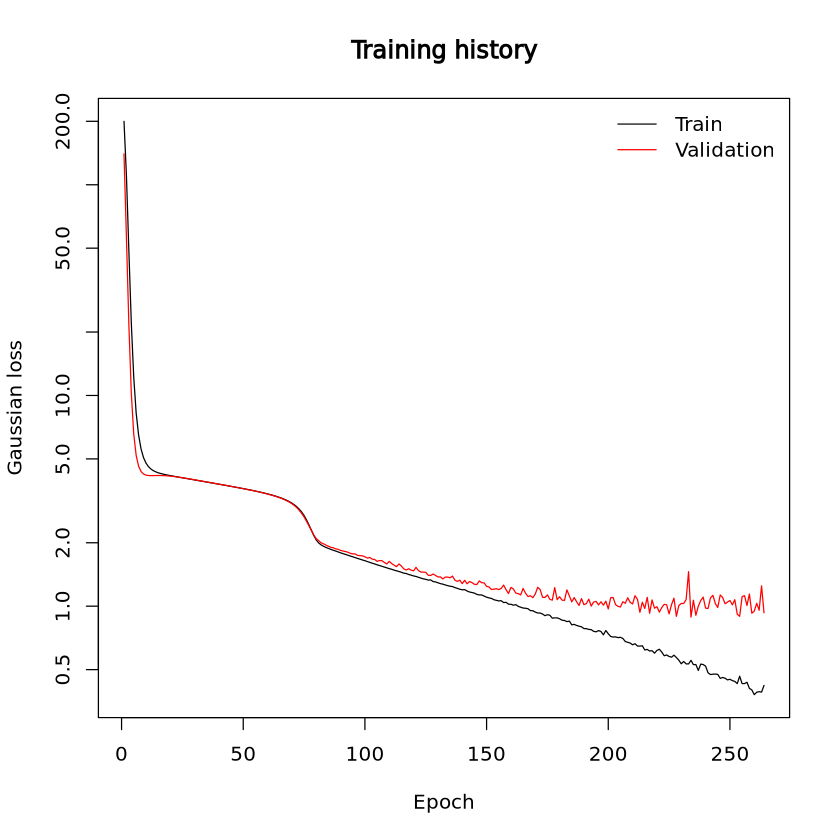

In [74]:
# ============================================================
# CNN1.SD: Station-wise training and independent prediction
# ============================================================

# Select stations:
# Use seq_len(nsta) for all stations or a single index for the notebook.
#stations_to_run <- seq_len(nsta)
stations_to_run <- 37

pred <- lapply(stations_to_run, function(z) {

  t0 <- Sys.time()

  # ----------------------------------------------------------
  # A. Select the target station
  # ----------------------------------------------------------

  id <- y$Metadata$station_id[z]

  message(
    "\nStation ", z, "/", nsta,
    " (ID: ", id, ")"
  )

  y_st <- subsetGrid(y, station.id = id) %>%
    redim(member = FALSE, loc = TRUE) %>%
    filterNA()

  message(
    "Valid observations: ",sum(is.finite(as.vector(y_st$Data))),"/", length(y_st$Data))

  save(y_st,file="y_st.rda")
  # ----------------------------------------------------------
  # B. Select the small predictor domain
  # ----------------------------------------------------------

  lon_lim <- c(y_st$xyCoords$x - 4.1,
               y_st$xyCoords$x + 4.1)

  lat_lim <- c(y_st$xyCoords$y - 4.1,
               y_st$xyCoords$y + 4.1)

  x_st <- subsetGrid(x_all,lonLim = lon_lim,latLim = lat_lim)

  # ----------------------------------------------------------
  # C. Standardize predictors and align dates
  # ----------------------------------------------------------

  x_st <- scaleGrid(x_st,type = "standardize") %>%intersectGrid(y_st, type = "temporal")

  # ----------------------------------------------------------
  # D. Prepare training data
  # ----------------------------------------------------------

  xyT <- prepareData.keras(
    x = x_st,
    y = y_st,
    first.connection = "conv",
    last.connection = "dense",
    channels = "last"
  )
  save(xyT,file='xyT_data.rda')

  # ----------------------------------------------------------
  # E. Define CNN1.SD architecture
  # ----------------------------------------------------------

  inputs <- layer_input(
    shape = c(
      getShape(x_st, "lat"),
      getShape(x_st, "lon"),
      getShape(x_st, "var")
    )
  )

  # Convolutional layers
  l1 <- layer_conv_2d(
    inputs,
    filters = 50,
    kernel_size = c(3, 3),
    activation = "relu",
    padding = "same"
  )

  l2 <- layer_conv_2d(
    l1,
    filters = 25,
    kernel_size = c(3, 3),
    activation = "relu",
    padding = "same"
  )

  l3 <- layer_conv_2d(
    l2,
    filters = 1,
    kernel_size = c(3, 3),
    activation = "relu",
    padding = "same"
  )

  l4 <- layer_flatten(l3)

  # Two output parameters for Gaussian loss
  l51 <- layer_dense(l4, units = 1, activation = "linear")
  l52 <- layer_dense(l4, units = 1, activation = "linear")

  outputs <- layer_concatenate(list(l51, l52))

  cnn_model <- keras_model(
    inputs = inputs,
    outputs = outputs
  )

  # ----------------------------------------------------------
  # F. Train the CNN
  # ----------------------------------------------------------

  model_file <- file.path(
    filepath,
    paste0("cnn_stationID_", id,
      y_st$Variable$varName,
      summer, "_", activation, "_CNN10_SD.h5"
    )
  )

  res_train <- downscaleTrain.keras.history(
    obj = xyT,model = cnn_model,clear.session = TRUE,
    compile.args = list(
      loss = distribution_fun,
      optimizer = optimizer_adam(learning_rate = learning_rate)),fit.args = list(
      batch_size = batch_size,
      epochs = max_epochs,
      validation_split = 0.1,
      verbose = 1,
      callbacks = list(
        callback_early_stopping(
          monitor = "val_loss",
          patience = patience,
          restore_best_weights = TRUE
        ),

        callback_model_checkpoint(
          filepath = model_file,
          monitor = "val_loss",
          save_best_only = TRUE
        )
      )
    )
  )

  # Save training history
  history <- res_train$history

  # ----------------------------------------------------------
  # G. Prepare predictors for the independent period
  # ----------------------------------------------------------

  x_ind <- subsetGrid(
    x_2024,
    lonLim = lon_lim,
    latLim = lat_lim
  )

  # x_2024 must already be standardized using
  # the training-period reference statistics.
  xyt <- prepareNewData.keras(x_ind, xyT)
  save(xyt,file='xyt_data.rda')
  # ----------------------------------------------------------
  # H. Generate independent predictions
  # ----------------------------------------------------------

  pred_st <- downscalePredict.keras(
    newdata = xyt,
    C4R.template = y_st,
    clear.session = TRUE,
    loss = paste0(distribution, "Loss"),
    model = list(
      filepath = model_file,
      custom_objects = c(
        "custom_loss" = distribution_fun
      )
    )
  )

  # Extract the predicted TWx variable
  pred_st <- subsetGrid(pred_st, var = "twmax1")

  pred_st$Variable$varName <- y_st$Variable$varName

  # ----------------------------------------------------------
  # I. Save station results
  # ----------------------------------------------------------

  output_file <- file.path(
    filepath,
    paste0(
      var, id, summer, "_",
      activation, "_CNN10_SD_train.rda"
    )
  )

  save(
    pred_st,
    history,
    file = output_file
  )

plot(
  history$loss,
  type = "l",
  log = "y",
  col = "black",
  xlab = "Epoch",
  ylab = "Gaussian loss",
  main = "Training history"
)

lines(history$val_loss, col = "red")

legend(
  "topright",
  legend = c("Train", "Validation"),
  col = c("black", "red"),
  lty = 1,
  bty = "n"
)

loss <- as.numeric(unlist(history$loss))
val_loss <- as.numeric(unlist(history$val_loss))

cat("Total epochs:", length(loss), "\n")
cat("Best epoch:", which.min(val_loss), "\n")
cat("Minimum validation loss:", min(val_loss), "\n")
cat("Final validation loss:", tail(val_loss, 1), "\n")
  # ----------------------------------------------------------
  # J. Report computational time
  # ----------------------------------------------------------

  elapsed <- as.numeric(
    difftime(Sys.time(), t0, units = "mins")
  )

  message(
    "Station ", z, "/", nsta,
    " completed in ", round(elapsed, 2), " min"
  )

  return(pred_st)

})

# ============================================================
# Combine predictions from all selected stations
# ============================================================

#pred_all <- bindGrid(
#  pred,
#  dimension = "loc"
#)

## 5. Visualize training
The training history can be used to inspect convergence and identify the selected epoch.

In [64]:
pred_summer_2024=pred[[1]]

pad applied on the interval: day



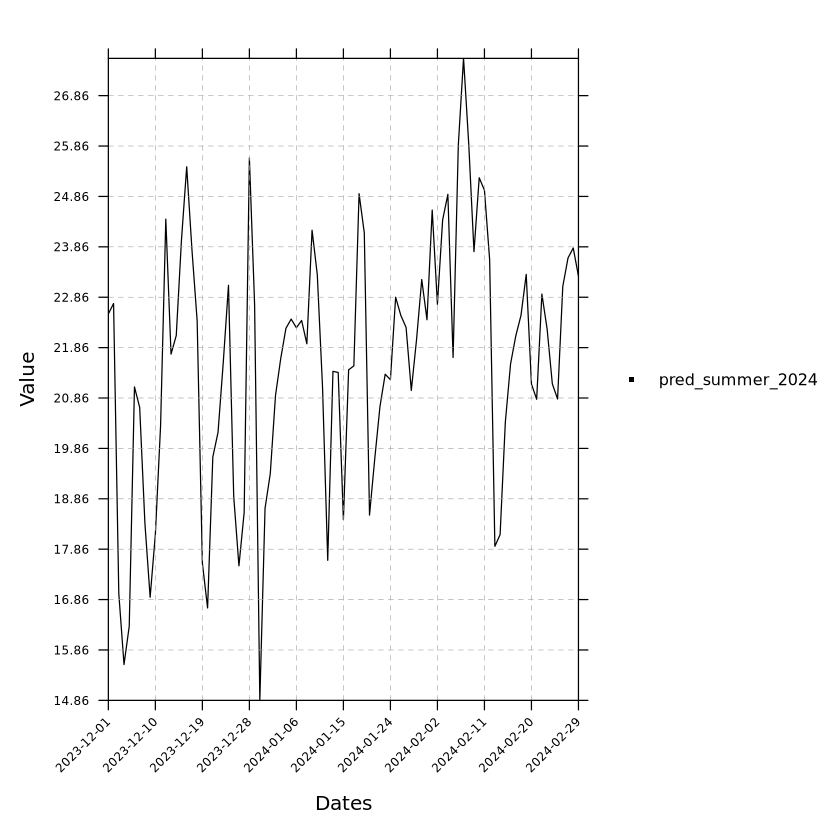

In [65]:
temporalPlot(pred_summer_2024)

In [66]:
y_summer_2024 <- load_one(file.path(base_path, "TWx", "new_station_data", "y_files_23_24.Rdata"))%>% filterNA()
y_summer_2024 <- subsetGrid(y_summer_2024,station.id =y$Metadata$station_id[stations_to_run],season=c(12,1,2))

NOTE: Some of the specified dimensions do not exist in the grid

NOTE: Some of the specified dimensions do not exist in the grid



In [67]:
y_summer_2024 <- intersectGrid(y_summer_2024,pred_summer_2024,type = 'temporal',which.return = 1)
pred_summer_2024=intersectGrid(pred_summer_2024,y_summer_2024,type = 'temporal',which.return = 1)

pad applied on the interval: day



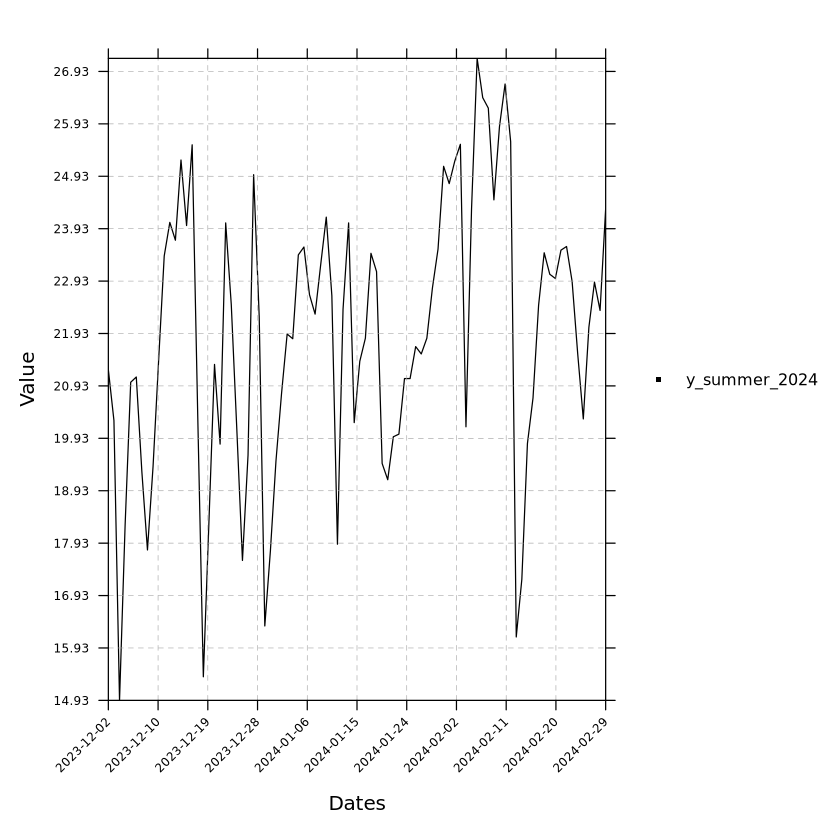

In [68]:
temporalPlot(y_summer_2024)

In [69]:
# Extract observations and predictions
obs <-y_summer_2024$Data
sim<-pred_summer_2024$Data

# Evaluation metrics
rmse <- sqrt(mean((sim - obs)^2))
bias <- mean(sim - obs)
nrmse <- rmse / sd(obs)
correlation <- cor(obs, sim)

data.frame(
  RMSE = round(rmse, 2),
  nRMSE = round(nrmse, 2),
  Bias = round(bias, 2),
  Correlation = round(correlation, 2)
)

RMSE,nRMSE,Bias,Correlation
<dbl>,<dbl>,<dbl>,<dbl>
1.39,0.53,-0.33,0.86


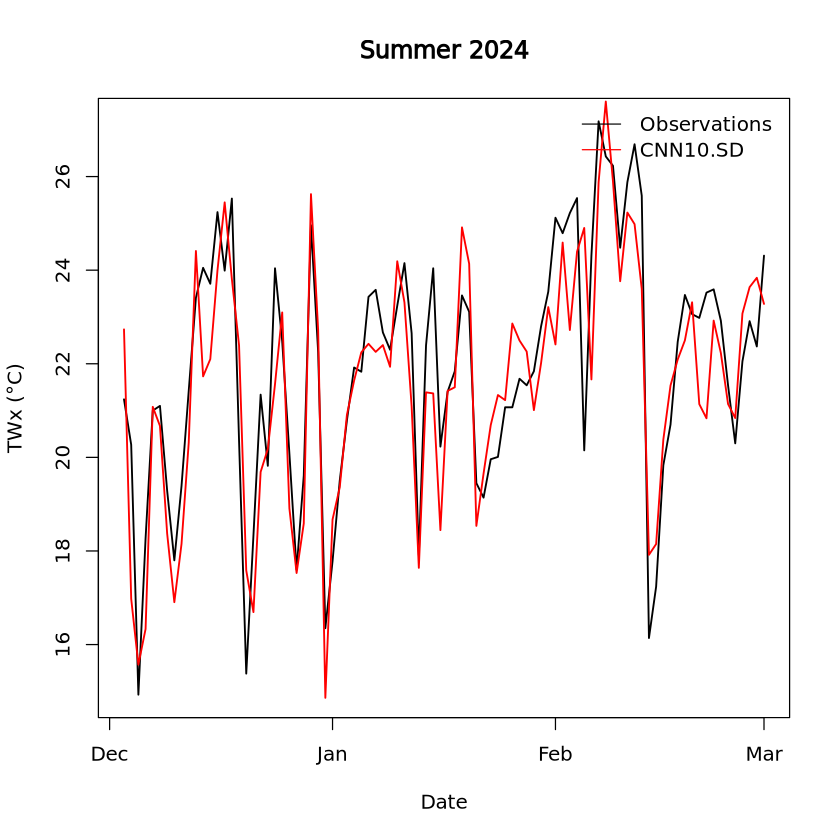

In [70]:
dates <- as.Date(y_summer_2024$Dates$end)

plot(
  dates, obs,
  type = "l",
  col = "black",
  lwd = 1.5,
  xlab = "Date",
  ylab = "TWx (°C)",
  main = "Summer 2024"
)

lines(dates, sim, col = "red", lwd = 1.5)

legend(
  "topright",
  legend = c("Observations", "CNN10.SD"),
  col = c("black", "red"),
  lty = 1,
  bty = "n"
)

In [71]:
sessionInfo()

R version 4.3.3 (2024-02-29)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Rocky Linux 8.10 (Green Obsidian)

Matrix products: default
BLAS/LAPACK: /nfs/home/gmeteo/balmacedar/micromamba/envs/cnn-hs/lib/libopenblasp-r0.3.34.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8          LC_NUMERIC=C                 
 [3] LC_TIME=en_US.UTF-8           LC_COLLATE=en_US.UTF-8       
 [5] LC_MONETARY=en_US.UTF-8       LC_MESSAGES=en_US.UTF-8      
 [7] LC_PAPER=en_US.UTF-8          LC_NAME=en_US.UTF-8          
 [9] LC_ADDRESS=en_US.UTF-8        LC_TELEPHONE=en_US.UTF-8     
[11] LC_MEASUREMENT=en_US.UTF-8    LC_IDENTIFICATION=en_US.UTF-8

time zone: Europe/Madrid
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] magrittr_2.0.3         downscaleR.keras_1.1.1 downscaleR_3.3.4      
 [4] visualizeR_1.6.4       transformeR_2.2.2      loadeR_1.8.4          
 [7] clima

6. ## Reproducibility notes

- **Single station:** change `stations_to_run` to use another of the 43 stations.
- **Domain:** the ±4.1° crop follows the provided example; the resulting number of grid cells depends on the underlying grid.
- **TWx:** the station observation file must contain the revised index calculated from 3-hourly measurements.
- **Cross-validation:** reproducing the paper's metrics requires fitting separate models for each fold and preparing the data appropriately for each period.
- **Final training:** the original script also fits models for different periods; this notebook uses one training fit and apply to only one austral summer (December 2023- January/February 2024).
- **Compatibility:** `.h5` files, custom functions, and the structure of `training_history` may require changes depending on the installed versions of `keras`, `tensorflow`, and `downscaleR.keras`.
- **Prediction:** computing RMSE and bias for the independent summer also requires 2024 station observations, which are not included among the specified input files.